# Tarea 1, Parte 1. Recolección de noticias de El Comercio

**Pregunta guía.** ¿Se pueden convertir titulares peruanos en un clasificador de noticias?

| | |
|---|---|
| Opción elegida | **B, El Comercio** |
| Fecha de descarga | 14 de octubre de 2026 |
| URL base | `https://elcomercio.pe` |
| Fuente de los enlaces | sitemaps de sección `https://elcomercio.pe/sitemap/web/<seccion>/?outputType=xml` |
| Categorías | `politica`, `economia`, `deportes`, `ciencia_tecnologia` |

**Por qué sitemaps y no RSS.** El `robots.txt` de El Comercio solo prohíbe a los bots en general las rutas `/catalogo/`, `/buscar/` y parte de `/archivo/`. Además, el propio archivo declara un sitemap por sección con las 100 notas más recientes de cada una. El RSS de sección también está permitido, pero el 14 de octubre traía pocas notas en algunas secciones, 18 en tecnología y 45 en política, por lo que no alcanzaba las 90 por categoría. Del sitemap salen los enlaces y de cada nota se leen sus etiquetas `<meta>` con el titular, la bajada, la fecha y la sección.

**Buenas prácticas.** Se usa un `User-Agent` que identifica el uso académico, una pausa de 1,5 segundos entre solicitudes y como máximo un reintento por enlace.

In [1]:
import time
from datetime import date
from pathlib import Path

import pandas as pd
import requests
from bs4 import BeautifulSoup

HEADERS = {"User-Agent": "Mozilla/5.0 (Tarea academica PUCP - curso Python Intermedio)"}
PAUSA = 1.5          # segundos entre solicitudes
BASE = "https://elcomercio.pe"

RAW = Path("datos/raw")
RAW.mkdir(parents=True, exist_ok=True)

print("Fecha de descarga:", date.today())

Fecha de descarga: 2026-10-14


## 1. Revisar `robots.txt`

Antes de pedir nada, revisamos qué permite el medio.

In [2]:
robots = requests.get(f"{BASE}/robots.txt", headers=HEADERS, timeout=30).text
(RAW / "robots_elcomercio.txt").write_text(robots, encoding="utf-8")

# Reglas para todos los bots (User-agent: *) y los sitemaps de las secciones que usaremos
reglas = robots.split("User-agent: *")[1].split("#")[0]
print(reglas.strip())
for linea in robots.splitlines():
    if linea.startswith("Sitemap:") and "/sitemap/" in linea and any(f"/{s}/" in linea for s in ["politica", "economia", "deporte-total", "tecnologia"]):
        print(linea)

Disallow: /catalogo/
Disallow: /buscar/
Disallow: /archivo/todas/19*
Disallow: /archivo/todas/200*
Sitemap: https://elcomercio.pe/sitemap/politica/?outputType=xml
Sitemap: https://elcomercio.pe/sitemap/tecnologia/?outputType=xml
Sitemap: https://elcomercio.pe/sitemap/economia/?outputType=xml
Sitemap: https://elcomercio.pe/sitemap/deporte-total/?outputType=xml


## 2. Enlaces desde los sitemaps de sección

Usamos una sección por cada categoría de la tarea. El sitemap es un XML con una etiqueta `<loc>` por nota. Cada XML se guarda tal cual en `datos/raw/` como respaldo crudo. Si el respaldo ya existe se lee de ahí, de modo que al volver a ejecutar el notebook se usan los mismos enlaces del día de descarga.

In [3]:
import warnings
from bs4 import XMLParsedAsHTMLWarning

# El sitemap es XML, pero html.parser basta para leer sus etiquetas <loc>
warnings.filterwarnings("ignore", category=XMLParsedAsHTMLWarning)

SECCIONES = ["politica", "economia", "deporte-total", "tecnologia"]

def obtener(url):
    """GET con pausa y como máximo un reintento."""
    for intento in range(2):
        try:
            r = requests.get(url, headers=HEADERS, timeout=30)
            time.sleep(PAUSA)
            if r.status_code == 200:
                return r.text
        except requests.RequestException:
            time.sleep(PAUSA)
    return None

enlaces = []
for seccion in SECCIONES:
    archivo = RAW / f"sitemap_{seccion}.xml"
    if not archivo.exists():
        archivo.write_text(obtener(f"{BASE}/sitemap/web/{seccion}/?outputType=xml"), encoding="utf-8")
    xml = archivo.read_text(encoding="utf-8")
    locs = [loc.text.strip() for loc in BeautifulSoup(xml, "html.parser").find_all("loc")]
    enlaces += [{"seccion_sitemap": seccion, "url": u} for u in locs]
    print(f"{seccion:15} {len(locs)} enlaces")

enlaces = pd.DataFrame(enlaces)
enlaces.shape

politica        100 enlaces
economia        100 enlaces
deporte-total   100 enlaces
tecnologia      100 enlaces


(400, 2)

## 3. Leer cada nota

Probamos primero con una sola nota para ver qué trae. El titular y la bajada vienen en las etiquetas `og:title` y `og:description`, que el medio pone para redes sociales, y la fecha en `article:published_time`.

La `seccion_original` sale de la ruta de la URL, tal como la organiza el medio. Por ejemplo, `elcomercio.pe/economia/mercados/...` se convierte en `economia-mercados`.

In [4]:
def seccion_de_url(url):
    partes = url.replace(BASE, "").strip("/").split("/")
    return "-".join(partes[:2]) if len(partes) > 2 else partes[0]

def leer_nota(url):
    html = obtener(url)
    if html is None:
        return {"url": url, "error": "sin respuesta"}
    sopa = BeautifulSoup(html, "html.parser")

    def meta(nombre):
        etiqueta = sopa.find("meta", attrs={"property": nombre})
        if etiqueta is None:
            return ""
        return etiqueta.get("content", "")

    return {
        "titular": meta("og:title").strip(),
        "bajada": meta("og:description").strip(),
        "medio": "El Comercio",
        "seccion_original": seccion_de_url(url),
        "url": url,
        "fecha": meta("article:published_time")[:10],
        "error": "",
    }

leer_nota(enlaces.loc[0, "url"])

{'titular': 'Keiko Fujimori ratifica su respaldo al ministro César Astudillo y al jefe de la PNP Fredy López',
 'bajada': 'Keiko Fujimori ratificó su respaldo al ministro de Defensa, César Astudillo, y al comandante general de la Policía Nacional del Perú (PNP), Fredy López, durante una ceremonia de ascenso de cinco suboficiales reconocidos por su destacada labor en la lucha contra la delincuencia.',
 'medio': 'El Comercio',
 'seccion_original': 'politica-gobierno',
 'url': 'https://elcomercio.pe/politica/gobierno/keiko-fujimori-ratifica-su-respaldo-al-ministro-cesar-astudillo-y-al-jefe-de-la-pnp-ultimas-noticia/',
 'fecha': '2026-10-14',
 'error': ''}

Funciona. Ahora recorremos todos los enlaces. El avance se guarda cada 25 notas en `datos/raw/notas_crudo.csv`. Si el proceso se corta por un bloqueo o por falta de internet, al volver a correr la celda continúa desde donde quedó en vez de pedir todo otra vez.

In [5]:
CRUDO = RAW / "notas_crudo.csv"
crudo = pd.read_csv(CRUDO, keep_default_na=False) if CRUDO.exists() else pd.DataFrame()
hechas = set(crudo["url"]) if len(crudo) else set()
pendientes = [u for u in enlaces["url"] if u not in hechas]
print(f"Ya leídas: {len(hechas)}, pendientes: {len(pendientes)}")

nuevas = []
for i, url in enumerate(pendientes, 1):
    nuevas.append(leer_nota(url))
    if i % 25 == 0 or i == len(pendientes):
        crudo = pd.concat([crudo, pd.DataFrame(nuevas)], ignore_index=True)
        crudo.to_csv(CRUDO, index=False)
        nuevas = []
        print(f"{i}/{len(pendientes)}")

crudo = crudo.merge(enlaces, on="url", how="left")
crudo.shape

Ya leídas: 400, pendientes: 0


(400, 8)

In [6]:
crudo["error"].replace("", "ok").value_counts()

error
ok    400
Name: count, dtype: int64

In [7]:
crudo.head()

,titular,bajada,medio,seccion_original,url,fecha,error,seccion_sitemap
0,Keiko Fujimori ratifica su respaldo al ministr...,Keiko Fujimori ratificó su respaldo al ministr...,El Comercio,politica-gobierno,https://elcomercio.pe/politica/gobierno/keiko-...,2026-10-14,,politica
1,Juan Sheput: “El Congreso ha apostado por la c...,"El ministro de Trabajo y Promoción del Empleo,...",El Comercio,politica-gobierno,https://elcomercio.pe/politica/gobierno/juan-s...,2026-10-14,,politica
2,"“Grupos hostiles”, el factor DINI y otras acci...",El Senado debatirá el pedido de facultades leg...,El Comercio,politica,https://elcomercio.pe/politica/grupos-hostiles...,2026-10-14,,politica
3,Senadora Milagros Jáuregui a favor de analizar...,En el programa “Tenemos Que Hablar” de El Come...,El Comercio,politica-elecciones,https://elcomercio.pe/politica/elecciones/sena...,2026-10-14,,politica
4,Ley MAPE: Minem prevé presentar propuesta este...,El Minem presentará al Congreso su propuesta d...,El Comercio,politica,https://elcomercio.pe/politica/ley-mape-minem-...,2026-10-14,,politica


## 4. Limpieza

### 4.1 Duplicados y titulares vacíos

Una misma nota podría aparecer en dos sitemaps y alguna página podría no traer titular. Lo revisamos y guardamos cada descarte con su motivo.

In [8]:
df = crudo.copy()
descartes = []

dup = df["url"].duplicated()
descartes.append(df[dup].assign(motivo="URL duplicada"))
df = df[~dup]

vacio = df["titular"].str.strip() == ""
descartes.append(df[vacio].assign(motivo="titular vacío"))
df = df[~vacio]

print("URLs duplicadas:", dup.sum())
print("Titulares vacíos:", vacio.sum())
print("Errores de descarga:", (df["error"] != "").sum())
df.shape

URLs duplicadas: 0
Titulares vacíos: 0
Errores de descarga: 0


(400, 8)

### 4.2 De la sección del medio a las 4 categorías

La `seccion_original` es la ruta de la URL y la regla de equivalencia es explícita.

- `politica-*` y `elecciones` → **politica**
- `economia-*` → **economia**
- `deporte-total-*` → **deportes**
- `tecnologia-*` y `eldominical-ciencia` → **ciencia_tecnologia**
- Las columnas de opinión se **descartan**, ya que su título no describe el tema. Se reconocen porque la sección contiene `opinion` o porque la URL lo indica con `...-por-<autor>-opinion-noticia/`, que es como aparecen algunas columnas dentro de `economia/dia-1`.
- Las demás secciones, como `ecdata`, `bbc-news-mundo`, `archivo-elcomercio` y `ruedas-tuercas-automotriz`, también se **descartan**. Son secciones transversales que El Comercio incluye en el sitemap de una sección, pero que no pertenecen a ella. No se inventa una quinta categoría.

In [9]:
def categoria(seccion):
    if "opinion" in seccion:
        return None
    if seccion.startswith("deporte-total"):
        return "deportes"
    if seccion.startswith("politica") or seccion == "elecciones":
        return "politica"
    if seccion.startswith("economia"):
        return "economia"
    if seccion.startswith("tecnologia") or seccion == "eldominical-ciencia":
        return "ciencia_tecnologia"
    return None

df["etiqueta"] = df["seccion_original"].map(categoria)
df.loc[df["url"].str.contains("-opinion-"), "etiqueta"] = None

equivalencias = (
    df.groupby("seccion_original", dropna=False)
    .agg(etiqueta=("etiqueta", "first"), noticias=("url", "size"))
    .fillna({"etiqueta": "descartada"})
    .sort_values(["etiqueta", "noticias"], ascending=[True, False])
)
equivalencias

,etiqueta,noticias
seccion_original,,
tecnologia-actualidad,ciencia_tecnologia,38
tecnologia-inteligencia-artificial,ciencia_tecnologia,19
tecnologia-ciencias,ciencia_tecnologia,14
tecnologia-ciberseguridad,ciencia_tecnologia,7
tecnologia-ecologia,ciencia_tecnologia,4
tecnologia-gadgets,ciencia_tecnologia,4
tecnologia-moviles,ciencia_tecnologia,3
tecnologia-robotica,ciencia_tecnologia,2
tecnologia-videojuegos,ciencia_tecnologia,2


In [10]:
fuera = df["etiqueta"].isna()
es_opinion = df["seccion_original"].str.contains("opinion") | df["url"].str.contains("-opinion-")
motivo = es_opinion[fuera].map(
    {True: "columna de opinión", False: "sección fuera de las 4 categorías"}
)
descartes.append(df[fuera].assign(motivo=motivo))
df = df[~fuera]

descartes = pd.concat(descartes)
print(f"Noticias descargadas: {len(crudo)}, descartadas: {len(descartes)}, quedan: {len(df)}")
descartes["motivo"].value_counts()

Noticias descargadas: 400, descartadas: 25, quedan: 375


motivo
columna de opinión                   16
sección fuera de las 4 categorías     9
Name: count, dtype: int64

In [11]:
descartes[["seccion_original", "titular", "motivo"]]

,seccion_original,titular,motivo
7,ecdata,La dispersión del voto creció en las últimas e...,sección fuera de las 4 categorías
8,ecdata,Elecciones municipales 2026: Casi mil candidat...,sección fuera de las 4 categorías
19,opinion-columnistas,Una conferencia legislativa,columna de opinión
37,opinion-columnistas,"¡A serenarse, señora Fujimori!",columna de opinión
63,opinion-columnistas,La primera pulseada,columna de opinión
68,ecdata,Fuerza Popular en las elecciones subnacionales...,sección fuera de las 4 categorías
84,opinion-columnistas,“No vamos a darles ahora nada”,columna de opinión
107,ecdata,Fenómeno El Niño: Presupuesto para prevención ...,sección fuera de las 4 categorías
118,economia-opinion,La evolución de la confianza en los pagos,columna de opinión
120,economia-opinion,La gloria gastronómica que debemos multiplicar,columna de opinión


In [12]:
df["etiqueta"].value_counts()

etiqueta
deportes              98
ciencia_tecnologia    96
politica              93
economia              88
Name: count, dtype: int64

## 5. Análisis exploratorio

Cada gráfico se muestra con `fig.show()` y además se guarda con `fig.write_html()` en la carpeta `graficos/`, para poder abrirlo en el navegador. Además se muestra una imagen estática del mismo gráfico, porque GitHub no muestra los gráficos interactivos de Plotly.

In [13]:
import plotly.express as px
import plotly.io as pio

# Gráfico interactivo y, además, una imagen PNG que GitHub sí puede mostrar
pio.renderers.default = "plotly_mimetype+png"

Path("graficos").mkdir(exist_ok=True)

df["largo_titular"] = df["titular"].str.len()

# Nombres con tilde para los títulos de los gráficos
NOMBRES = {"politica": "política", "economia": "economía",
           "deportes": "deportes", "ciencia_tecnologia": "ciencia y tecnología"}
df["fecha"] = pd.to_datetime(df["fecha"])

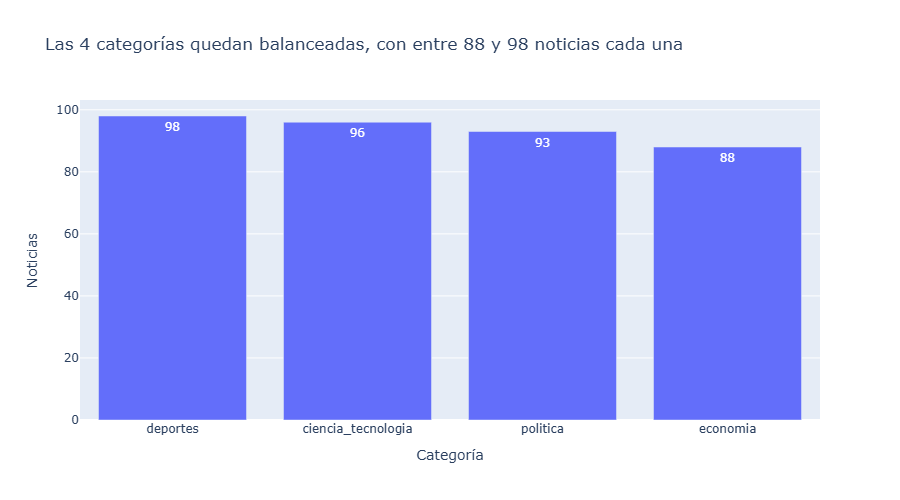

In [14]:
conteo = df["etiqueta"].value_counts().reset_index()
fig = px.bar(
    conteo, x="etiqueta", y="count", text="count",
    labels={"etiqueta": "Categoría", "count": "Noticias"},
    title=f"Las 4 categorías quedan balanceadas, con entre {conteo['count'].min()} y {conteo['count'].max()} noticias cada una",
)
fig.show()
fig.write_html("graficos/1_categorias.html")

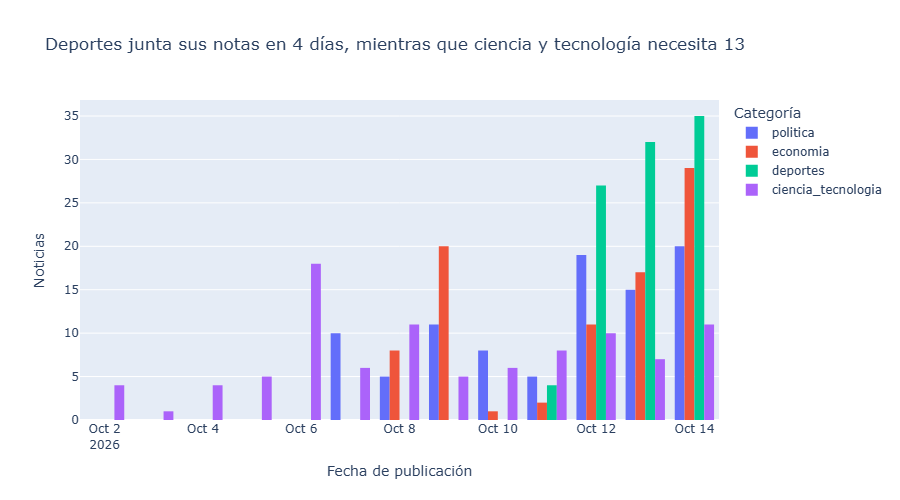

In [15]:
dias = df.groupby("etiqueta")["fecha"].nunique()
fig = px.histogram(
    df, x="fecha", color="etiqueta", barmode="group",
    labels={"fecha": "Fecha de publicación", "etiqueta": "Categoría", "count": "Noticias"},
    title=(f"Deportes junta sus notas en {dias['deportes']} días, "
           f"mientras que ciencia y tecnología necesita {dias['ciencia_tecnologia']}"),
)
fig.update_layout(yaxis_title="Noticias")
fig.show()
fig.write_html("graficos/2_fechas.html")

Como se trabaja con un solo medio, el segundo gráfico usa el rango de fechas. Cada sitemap trae las 100 notas más recientes de su sección, así que las secciones que publican más cubren menos días. Por eso el dataset es un corte del **2 al 14 de octubre de 2026** desigual por categoría, en el que deportes y política se concentran en la última semana.

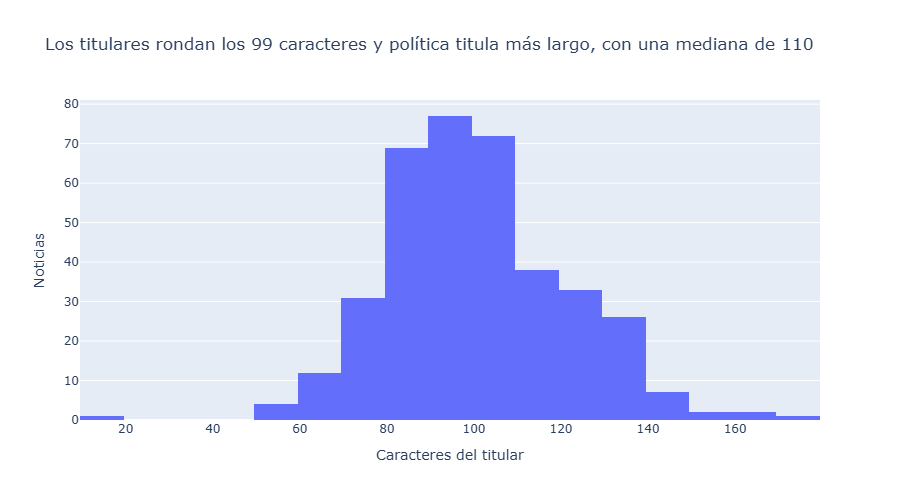

In [16]:
medianas = df.groupby("etiqueta")["largo_titular"].median()
fig = px.histogram(
    df, x="largo_titular", nbins=30,
    labels={"largo_titular": "Caracteres del titular"},
    title=(f"Los titulares rondan los {df['largo_titular'].median():.0f} caracteres "
           f"y {NOMBRES[medianas.idxmax()]} titula más largo, con una mediana de {medianas.max():.0f}"),
)
fig.update_layout(yaxis_title="Noticias")
fig.show()
fig.write_html("graficos/3_largo_titulares.html")

In [17]:
medianas.sort_values()

etiqueta
economia               92.5
ciencia_tecnologia     94.0
deportes               99.0
politica              110.0
Name: largo_titular, dtype: float64

## 6. Validación de los titulares más largos y más cortos

In [18]:
pd.set_option("display.max_colwidth", None)
df.sort_values("largo_titular", ascending=False).head(5)[["largo_titular", "etiqueta", "titular"]]

,largo_titular,etiqueta,titular
238,173,deportes,"Annia Cillóniz líder en su categoría en Caminos del Inca: “A veces nos toca esforzarnos el doble, pero como mujer tenemos la resiliencia para enfocarnos en nuestro objetivo”"
15,166,politica,"Keiko Fujimori sobre Álvaro Vargas Llosa: “Confío en que su trayectoria, experiencia y compromiso contribuirán a fortalecer relaciones bilaterales y lazos de amistad”"
11,160,politica,"Juan Sheput sobre eventual suspensión del viaje del papa León XIV al Perú: “Es posible, pero todavía no está la palabra definitiva, que corresponde al Vaticano”"
273,159,deportes,El “No quieren que Alianza salga campeón” de un furioso Guede y el mensaje de Gaibor al “verdadero hincha”: Lo que no se vio de la resurrección íntima en Cusco
65,153,politica,"Keiko Fujimori sobre Astudillo: “Le expreso mi total respaldo y gratitud por su valentía. Ministro, los perros ladran es una señal que estamos avanzando”"


In [19]:
df.sort_values("largo_titular").head(5)[["largo_titular", "etiqueta", "titular"]]

,largo_titular,etiqueta,titular
167,17,economia,Mi primer trabajo
260,50,deportes,David Alaba volvió a jugar tras tres meses de baja
193,50,economia,El juicio y la creatividad: las armas contra la IA
337,59,ciencia_tecnologia,¿Qué secreto de longevidad atesora una tortuga de 194 años?
325,59,ciencia_tecnologia,"Qué es la ""depresión sonriente"" y cómo puedes identificarla"


Los resultados son coherentes con el histograma. La cola derecha la forman titulares de **política y deportes que citan declaraciones completas**, y por eso política tiene la mediana más alta. La cola izquierda es corta. La encabeza una nota de **economía** con título de suplemento, *"Mi primer trabajo"*, de 17 caracteres, y el resto ronda los 50 a 60 caracteres repartidos entre categorías. Son titulares reales y bien leídos, no errores de extracción, así que se quedan. Las columnas de opinión, que eran las más cortas y menos informativas, ya se descartaron en el paso 4.

## 7. Exportación

Se guarda `datos/noticias.csv` con las 7 columnas pedidas y en ese orden.

In [20]:
COLUMNAS = ["titular", "bajada", "medio", "seccion_original", "url", "fecha", "etiqueta"]
noticias = df[COLUMNAS].copy()
noticias["fecha"] = noticias["fecha"].dt.strftime("%Y-%m-%d")
noticias.to_csv("datos/noticias.csv", index=False, encoding="utf-8")
print(noticias.shape)
noticias.head()

(375, 7)


,titular,bajada,medio,seccion_original,url,fecha,etiqueta
0,Keiko Fujimori ratifica su respaldo al ministro César Astudillo y al jefe de la PNP Fredy López,"Keiko Fujimori ratificó su respaldo al ministro de Defensa, César Astudillo, y al comandante general de la Policía Nacional del Perú (PNP), Fredy López, durante una ceremonia de ascenso de cinco suboficiales reconocidos por su destacada labor en la lucha contra la delincuencia.",El Comercio,politica-gobierno,https://elcomercio.pe/politica/gobierno/keiko-fujimori-ratifica-su-respaldo-al-ministro-cesar-astudillo-y-al-jefe-de-la-pnp-ultimas-noticia/,2026-10-14,politica
1,Juan Sheput: “El Congreso ha apostado por la coyuntura y no por las reformas de fondo” | Entrevista,"El ministro de Trabajo y Promoción del Empleo, Juan Sheput, sostuvo que, si el Congreso no aprueba ni la mitad de los puntos planteados por el gobierno en su solicitud de facultades, sería “un fracaso” para el Parlamento, sobre todo de la cámara de diputados. Agregó que esta instancia, prácticamente, “mutiló” la propuesta inicial.",El Comercio,politica-gobierno,https://elcomercio.pe/politica/gobierno/juan-sheput-el-congreso-ha-apostado-por-la-coyuntura-y-no-por-las-reformas-de-fondo-entrevista-apuesplan-noticia/,2026-10-14,politica
2,"“Grupos hostiles”, el factor DINI y otras acciones: estos son los ocho puntos que incorpora el predictamen del Senado","El Senado debatirá el pedido de facultades legislativas del Ejecutivo. El predictamen incorpora ocho puntos al texto aprobado por Diputados, con medidas sobre grupos hostiles, herramientas antiterroristas y fortalecimiento de la DINI.",El Comercio,politica,https://elcomercio.pe/politica/grupos-hostiles-mecanismos-antiterroristas-y-el-factor-dini-estos-son-los-nuevos-puntos-que-incluye-predictamen-del-senado-sobre-facultades-especiales-apuesplan-noticia/,2026-10-14,politica
3,"Senadora Milagros Jáuregui a favor de analizar una segunda vuelta para la Alcaldía de Lima, pero no para el actual proceso","En el programa “Tenemos Que Hablar” de El Comercio, la senadora Milagros Jáuregui (Renovación Popular) se mostró a favor de analizar una segunda vuelta para la Alcaldía de Lima, pero no para el actual proceso que lidera el candidato a primer regidor de su partido, Rafael López Aliaga.",El Comercio,politica-elecciones,https://elcomercio.pe/politica/elecciones/senadora-milagros-jauregui-a-favor-de-analizar-una-segunda-vuelta-para-la-alcaldia-de-lima-pero-no-para-el-actual-proceso-elecciones-regionales-y-municipales-2026-ultimas-noticia/,2026-10-14,politica
4,"Ley MAPE: Minem prevé presentar propuesta este jueves, ¿qué plantea y qué advierten los expertos sobre el Reinfo?","El Minem presentará al Congreso su propuesta de nueva Ley MAPE a casi dos meses del vencimiento del Reinfo, previsto para el 31 de diciembre de 2026. Conoce qué plantea el proyecto sobre la formalización minera, el régimen de consolidación hasta el 2028 y las críticas de especialistas y dirigentes de la minería informal.",El Comercio,politica,https://elcomercio.pe/politica/ley-mape-minem-preve-presentar-propuesta-este-jueves-que-plantea-y-que-advierten-los-expertos-sobre-el-reinfo-noticia/,2026-10-14,politica
